# Global Sensitivity of the In-Plane Elastic Buckling Load of Shallow Steel Arches

__Trong-Ha Nguyen__, Department of Civil Engineering, Vinh University, Vinh, Vietnam

Notebook: Claude (Anthropic) for P. Constantine, 2026

<br>

It runs in Python 3 with numpy, scipy and matplotlib and the [active_subspaces](https://github.com/paulcon/active_subspaces) library, version 1.0 or later, and takes a few seconds.

In [1]:
%matplotlib inline
import time

import numpy as np
import matplotlib.pyplot as plt
import active_subspaces as ac
import arch_buckling_model as am

SEED = 2020                       # the only seed in this notebook (also the seed of generate_data.py)
t_start = time.perf_counter()
labels = [r'$S$', r'$\Phi$', r'$E$', r'$D$', r'$B$', r'$t_w$', r'$t_f$']

### Summary

Nguyen [[1]](https://doi.org/10.48084/etasr.3833) computes Sobol' indices of the in-plane elastic buckling load of a circular steel I-section arch under uniform compression, using the closed-form buckling formulas of Pi, Bradford and Uy [[2]](https://doi.org/10.1016/S0020-7683(01)00209-8) for a fixed and a pin-ended shallow arch, with the arch length, included angle, Young's modulus and four cross-section dimensions uniform on ±10 % ranges. We rebuild that model in numpy with exact gradients and compute the active subspace of the buckling load from 1000 samples for both support conditions. The fixed arch has a one-dimensional active subspace (eigenvalue ratio about 400) along which the load is nearly linear; the pin-ended arch, whose formula switches branch inside the input box, has a clear two-dimensional subspace (eigenvalue ratios 31 and 53) whose second direction follows the arch's slenderness.

### Active subspaces in brief

For a function $f(\mathbf x)$ of $m$ normalized inputs with density $\rho$, the active subspace is spanned by the leading eigenvectors of $\mathbf C = \int \nabla f\,\nabla f^T \rho\,d\mathbf x = \mathbf W\Lambda\mathbf W^T$. If the first $n$ eigenvalues are much larger than the rest, $f$ varies mostly along the active variables $\mathbf y = \mathbf W_1^T\mathbf x$ and is nearly constant along $\mathbf W_2^T\mathbf x$, so a plot of $f$ against $\mathbf y$ (a *sufficient summary plot*) shows the main trend, and a surrogate in $\mathbf y$ can replace $f$. We estimate $\mathbf C$ by the sample average of gradient outer products and assess it with the bootstrap. See P. G. Constantine, [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860), SIAM, 2015.

### The model

The paper [[1]](https://doi.org/10.48084/etasr.3833) (pp. 6476–6477, Eqs. 1–6) takes from Pi, Bradford and Uy [[2]](https://doi.org/10.1016/S0020-7683(01)00209-8) the in-plane elastic buckling load $N_{acr}$ of a shallow circular arch (included angle $\Phi < 90^\circ$) under uniform compression. With arch length $S$ and the radius of gyration $r_x = \sqrt{I/A}$ of the cross-section, the modified slenderness is

$$\lambda = \frac{S\,\Phi}{4\,r_x}, \qquad N_{cr} = \frac{\pi^2 E I}{(kS)^2},\quad k = 0.35 \text{ (fixed)},\ 0.5 \text{ (pin-ended)},$$

where $N_{cr}$ is the second-mode flexural buckling load of a column of length $S$. The buckling load is $N_{acr} = c(\lambda)\,N_{cr}$ with

$$
c_{\text{pin}}(\lambda) = \begin{cases} 0.15 + 0.006\lambda^2, & 3.88 < \lambda < 9.38,\\ 0.26 + 0.74\sqrt{1 - 0.63\pi^4/\lambda^2}, & \lambda > 9.38,\end{cases}
\qquad
c_{\text{fix}}(\lambda) = \begin{cases} 0.36 + 0.0011\lambda^2, & 9.87 < \lambda < 18.6,\\ 0.6 + 0.4\sqrt{1 - 3.109\pi^4/\lambda^2}, & \lambda > 18.6.\end{cases}
$$

The square roots are read from the typeset equations (2)–(3); the PDF's text layer drops them. The two fixed-arch branches meet continuously at $\lambda = 18.6$, but the pin-ended branches do not: at $\lambda = 9.38$, $c$ drops from 0.6779 to 0.6670 (1.6 %), presumably from rounding of the constants.

**Choices we made** (the paper does not settle them; see `DATA.md`):

- *Independent inputs.* The paper samples $S$, $\Phi$ and the span $L$ independently (Table II), but $L$ does not appear in Eqs. (1)–(6), and for a circular arch $L = 2(S/\Phi)\sin(\Phi/2)$ is fixed by $S$ and $\Phi$. Its Table II range, 9–10 m, is not even possible: a chord cannot be longer than its arc, and $S \le 7.679$ m. We keep the seven inputs that enter the formulas, $\mathbf x = (S, \Phi, E, D, B, t_w, t_f)$, as independent uniforms, and report the span they imply.
- *Young's modulus.* Table II prints 18E5–22E5 MPa, ten times the modulus of steel; we use $1.8\times10^5$–$2.2\times10^5$ MPa. The subspace does not depend on this: a scale factor on $E$ changes neither its relative range nor the normalized gradients.
- *Section properties.* The paper does not write $A$ and $I$; we use a doubly symmetric I-section without root fillets, $A = 2Bt_f + (D-2t_f)t_w$, $I = [BD^3 - (B-t_w)(D-2t_f)^3]/12$.
- *Validity range.* Over the input box $\lambda$ lies in $[8.06, 15.23]$. For the fixed arch the first branch is stated only for $\lambda > 9.87$; about 12 % of the box lies below, where we use the same polynomial (the paper does not say what it did). The fixed arch never reaches its second branch ($\lambda < 18.6$). For the pin-ended arch the box straddles the switch at $\lambda = 9.38$.

**Quantity of interest.** $N_{acr}$ in kN for the fixed arch (Case 1 of the paper) and the pin-ended arch (Case 2). The gradients $\partial N_{acr}/\partial x_j$ are exact (chain rule through $\lambda$, $A$, $I$ and $N_{cr}$; on each branch the model is smooth). At the pin-ended switch the load jumps, and gradients do not see the jump.

The table below is built from `arch_buckling_model.py`.

In [2]:
print(f"{'input':6s} {'units':5s} {'lower':>9s} {'upper':>9s}  description")
for j, n in enumerate(am.NAMES):
    print(f'{n:6s} {am.UNITS[j]:5s} {am.LOWER[j]:9.4g} {am.UPPER[j]:9.4g}  {am.DESCRIPTIONS[j]}')
corners = np.array(np.meshgrid(*zip(am.LOWER, am.UPPER))).reshape(7, -1).T
lam_c = am.slenderness(corners)
print(f'\nlambda over the box (corners): [{lam_c.min():.2f}, {lam_c.max():.2f}]; '
      f'implied span L = 2 (S/Phi) sin(Phi/2): [{am.implied_span(corners).min():.2f}, '
      f'{am.implied_span(corners).max():.2f}] m (Table II: {am.L_TABLE[0]:.2f}-{am.L_TABLE[1]:.2f} m)')
for case in ('fixed', 'pinned'):
    c = am.CASES[case]
    l = c['switch']
    print(f"{case:6s}: k = {c['k']}, branch switch at lambda = {l}: "
          f"c = {c['a'] + c['b']*l**2:.4f} below, {c['p'] + c['q']*np.sqrt(1 - c['alpha']*np.pi**4/l**2):.4f} above; "
          f"lower validity limit lambda = {c['low']}")

input  units     lower     upper  description
S      m         6.283     7.679  arch length (along the axis)
Phi    rad       0.628     0.768  included angle
E      MPa     1.8e+05   2.2e+05  Young's modulus
D      m         0.235     0.287  section depth
B      m         0.136     0.166  flange width
tw     m         0.007     0.008  web thickness
tf     m         0.011     0.014  flange thickness

lambda over the box (corners): [8.06, 15.23]; implied span L = 2 (S/Phi) sin(Phi/2): [6.13, 7.55] m (Table II: 9.00-10.00 m)
fixed : k = 0.35, branch switch at lambda = 18.6: c = 0.7406 below, 0.7412 above; lower validity limit lambda = 9.87
pinned: k = 0.5, branch switch at lambda = 9.38: c = 0.6779 below, 0.6670 above; lower validity limit lambda = 3.88


### Load data

`generate_data.py` drew $M = 1000$ independent uniform samples of the seven inputs (seed 2020) and wrote the physical inputs, both buckling loads with the slenderness, and the exact gradients with respect to the physical inputs (see `DATA.md`).

In [3]:
X = np.loadtxt('inputs.csv', delimiter=',')                  # (M, 7) physical inputs
out = np.loadtxt('outputs.csv', delimiter=',')               # (M, 3) N fixed (kN), N pinned (kN), lambda
G_fix = np.loadtxt('gradients_fixed.csv', delimiter=',')     # (M, 7) dN_fixed/dx in kN per input unit
G_pin = np.loadtxt('gradients_pinned.csv', delimiter=',')    # (M, 7) dN_pinned/dx
f_fix, f_pin, lam = out.T
print(f'inputs {X.shape}, outputs {out.shape}, gradients {G_fix.shape} and {G_pin.shape}')

inputs (1000, 7), outputs (1000, 3), gradients (1000, 7) and (1000, 7)


We check the files against the model, the exact gradients against central finite differences (relative step $10^{-6}$ of each input's range), and count the samples on each branch, in the data and in $10^6$ fresh samples. A difference across the pin-ended switch would measure the jump, not the derivative, so the check leaves out samples with $|\lambda - 9.38| < 10^{-4}$ (none of these 1000).

In [4]:
h = 1e-6*(am.UPPER - am.LOWER)
far = np.abs(lam - am.CASES['pinned']['switch']) > 1e-4
for case, f, G in (('fixed', f_fix, G_fix), ('pinned', f_pin, G_pin)):
    G_fd = np.column_stack([(am.buckling_load(X + h[j]*e, case) - am.buckling_load(X - h[j]*e, case))/(2*h[j])
                            for j, e in enumerate(np.eye(7))])
    err = np.linalg.norm(G_fd - G, axis=1)/np.linalg.norm(G, axis=1)
    print(f'{case:6s}: max |model - file|/N = {np.max(np.abs(am.buckling_load(X, case) - f)/f):.1e}; '
          f'gradient vs central differences: max relative error {err[far].max():.1e} '
          f'({far.sum()} samples), median {np.median(err[far]):.1e}; N in [{f.min():.0f}, {f.max():.0f}] kN')
X_big = am.sample(10**6, SEED + 1)
for case in ('fixed', 'pinned'):
    b, bb = am.branch(X, case), am.branch(X_big, case)
    print(f'{case:6s} branch fractions (below validity, branch 1, branch 2): data '
          f'{[round(float(np.mean(b == k)), 3) for k in (0, 1, 2)]}, 1e6 samples {[round(float(np.mean(bb == k)), 4) for k in (0, 1, 2)]}')

fixed : max |model - file|/N = 9.1e-16; gradient vs central differences: max relative error 6.3e-09 (1000 samples), median 1.5e-09; N in [7060, 16538] kN
pinned: max |model - file|/N = 7.6e-16; gradient vs central differences: max relative error 6.0e-09 (1000 samples), median 1.5e-09; N in [5428, 12593] kN


fixed  branch fractions (below validity, branch 1, branch 2): data [0.113, 0.887, 0.0], 1e6 samples [0.122, 0.878, 0.0]


pinned branch fractions (below validity, branch 1, branch 2): data [0.0, 0.041, 0.959], 1e6 samples [0.0, 0.0448, 0.9552]


### Estimate the subspace

The model is closed-form with exact gradients, so we use the gradient-based estimator (`estimator="as"`), $\hat{\mathbf C} = \frac1M\sum_i \nabla f_i\nabla f_i^T$ in normalized coordinates. The input space is `ac.Uniform` on the bounds above; we pass the physical samples and physical gradients, and the library normalizes both to $[-1,1]^7$ once. We use 500 bootstrap replicates and the library's default dimension rule (largest linear eigenvalue gap $\lambda_k - \lambda_{k+1}$), and orient each eigenvector so that it has a positive inner product with the mean gradient ($N_{acr}$ increases along $\mathbf w_1$).

In [5]:
space = ac.Uniform(am.LOWER, am.UPPER, names=list(am.NAMES))
subs = {}
for case, f, G in (('fixed', f_fix, G_fix), ('pinned', f_pin, G_pin)):
    s = ac.active_subspace(space=space, X=X, f=f, grads=G, estimator='as', nboot=500, rng=SEED)
    subs[case] = ac.orient(s, by='mean_gradient', grads=G, columns=7)
    l = subs[case].eigenvalues
    print(f'{case:6s}: eigenvalues {np.array2string(l, precision=3)}')
    print(f'        n = {subs[case].n} (gap rule); lambda_1/lambda_2 = {l[0]/l[1]:.1f}, '
          f'lambda_2/lambda_3 = {l[1]/l[2]:.1f}, lambda_1/sum = {l[0]/l.sum():.4f}')
sub_f, sub_p = subs['fixed'], subs['pinned']

fixed : eigenvalues [9.685e+06 2.411e+04 5.171e+03 4.189e+03 2.001e+03 2.853e+02 7.265e+00]
        n = 1 (gap rule); lambda_1/lambda_2 = 401.7, lambda_2/lambda_3 = 4.7, lambda_1/sum = 0.9963


pinned: eigenvalues [4.934e+06 1.596e+05 3.006e+03 2.319e+03 1.994e+03 8.040e+02 1.418e+01]
        n = 1 (gap rule); lambda_1/lambda_2 = 30.9, lambda_2/lambda_3 = 53.1, lambda_1/sum = 0.9671


### Results: fixed arch (Case 1)

**Eigenvalues.** The figure shows the eigenvalues with a 95 % bootstrap band.

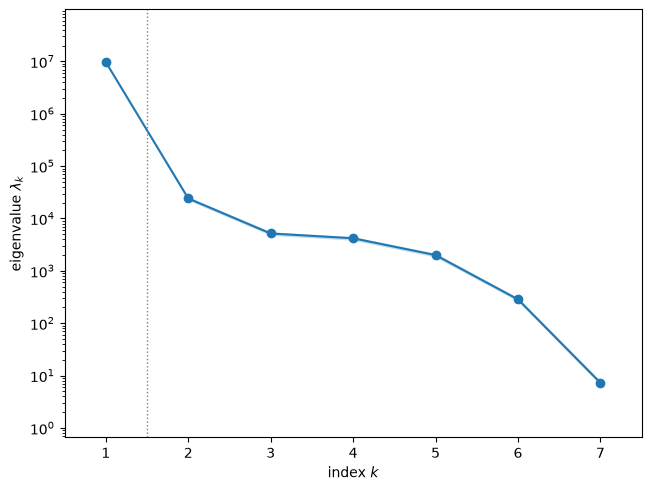

In [6]:
fig, ax = ac.plotting.plot_eigenvalues(sub_f)
plt.close(fig)
fig

For the fixed arch $\lambda_1 = 9.685\times10^{6}$ (kN$^2$, normalized coordinates) and $\lambda_1/\lambda_2 = 401.7$: the first eigenvalue carries 99.63 % of $\operatorname{tr}\mathbf C$. The next ratio, $\lambda_2/\lambda_3 = 4.7$, is small, and the gap rule picks $n = 1$.

bootstrap mean subspace distance, k = 1..6: [1.8e-03 2.4e-02 1.2e-01 4.5e-02 1.6e-02 5.1e-03]


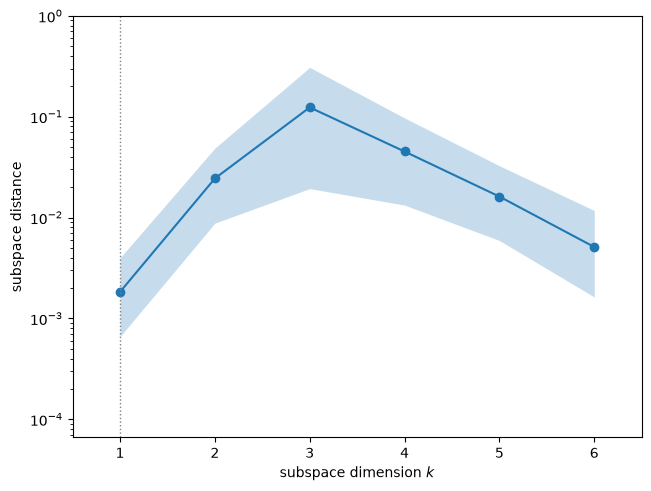

In [7]:
fig, ax = ac.plotting.plot_subspace_errors(sub_f)
plt.close(fig)
print('bootstrap mean subspace distance, k = 1..6:',
      np.array2string(sub_f.bootstrap_distances.mean(axis=0), formatter={'float_kind': '{:.1e}'.format}))
fig

The bootstrap mean distance of the one-dimensional subspace is $1.8\times10^{-3}$, so 1000 samples determine $\mathbf w_1$ to about three digits. The distances for $k = 2, \dots, 6$ range from $5.1\times10^{-3}$ to 0.12, the largest at $k = 3$, behind the smallest ratio ($\lambda_3/\lambda_4 = 1.2$).

w1 (fixed): S -0.528, Phi +0.192, E +0.356, D +0.613, B +0.292, tw +0.042, tf +0.308


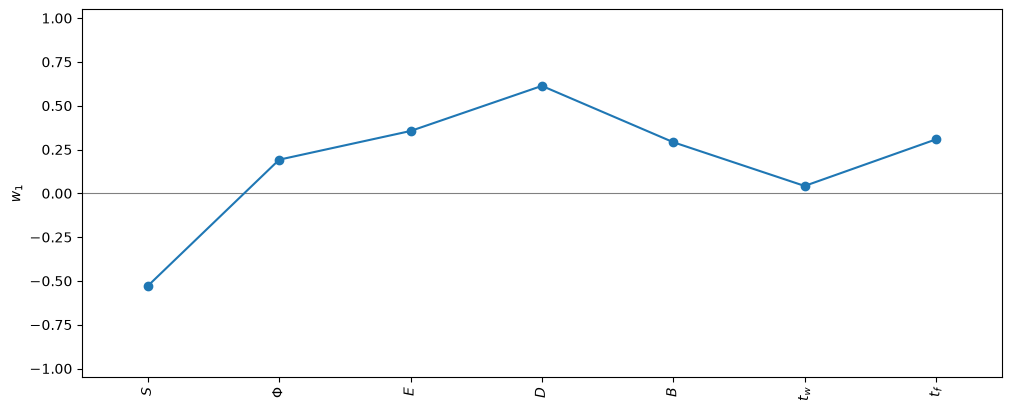

In [8]:
fig, axes = ac.plotting.plot_eigenvectors(sub_f, indices=[0], labels=labels, figsize=(10, 4))
plt.close(fig)
w1f = sub_f.W[:, 0]
print('w1 (fixed):', ', '.join(f'{n} {w:+.3f}' for n, w in zip(am.NAMES, w1f)))
fig

The first eigenvector weights the section depth most ($D$: +0.613), then the arch length ($S$: −0.528), the modulus ($E$: +0.356), the flange thickness ($t_f$: +0.308), the flange width ($B$: +0.292) and the included angle ($\Phi$: +0.192); the web thickness hardly matters (+0.042). A longer arch lowers the load through $N_{cr}\propto 1/S^2$, while a larger $\Phi$ raises it only through the slenderness, $\lambda \propto S\Phi$.

y1 range [-1.55, 1.50]; correlation of N with y1: 0.9936; 113 samples with lambda <= 9.87, at y1 in [-0.40, 1.44]


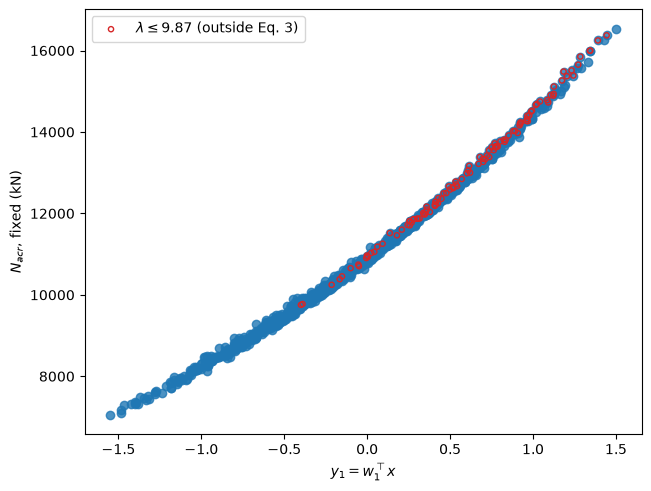

In [9]:
fig, ax = ac.plotting.plot_sufficient_summary(sub_f, X=X, f=f_fix, dims=1, qoi_label=r'$N_{acr}$, fixed (kN)')
y_f = space.to_normalized(X) @ w1f
low = am.branch(X, 'fixed') == 0
ax.scatter(y_f[low], f_fix[low], s=14, facecolors='none', edgecolors='C3', label=r'$\lambda \leq 9.87$ (outside Eq. 3)')
ax.legend()
plt.close(fig)
r = np.corrcoef(y_f, f_fix)[0, 1]
print(f'y1 range [{y_f.min():.2f}, {y_f.max():.2f}]; correlation of N with y1: {r:.4f}; '
      f'{low.sum()} samples with lambda <= 9.87, at y1 in [{y_f[low].min():.2f}, {y_f[low].max():.2f}]')
fig

The fixed-arch load is close to a linear function of the single active variable $y_1 = \mathbf w_1^T\mathbf x$ (correlation 0.9936 over $y_1 \in [-1.55, 1.50]$), with a slight upward curvature. The 113 samples with $\lambda \le 9.87$ (red circles), where Eq. (3) is applied outside its stated range, lie on the same curve, all at $y_1 \ge -0.40$: a deep section (large $D$) both raises the load and lowers $\lambda$.

Restricting the estimate to the samples inside the validity range changes little:

In [10]:
ok = ~low
sub_ok = ac.active_subspace(space=space, X=X[ok], f=f_fix[ok], grads=G_fix[ok], estimator='as', nboot=500, rng=SEED)
l = sub_ok.eigenvalues
print(f'{ok.sum()} samples with lambda > 9.87: lambda_1/lambda_2 = {l[0]/l[1]:.1f}, '
      f'|w1(valid) . w1(all)| = {abs(sub_ok.W[:, 0] @ w1f):.5f}')

887 samples with lambda > 9.87: lambda_1/lambda_2 = 539.4, |w1(valid) . w1(all)| = 0.99991


On the 887 samples inside the validity range the ratio is $\lambda_1/\lambda_2 = 539.4$, and the first eigenvector agrees with the one from all samples to $|\mathbf w_1^{\text{valid}}\cdot\mathbf w_1| = 0.99991$.

### Results: pin-ended arch (Case 2)

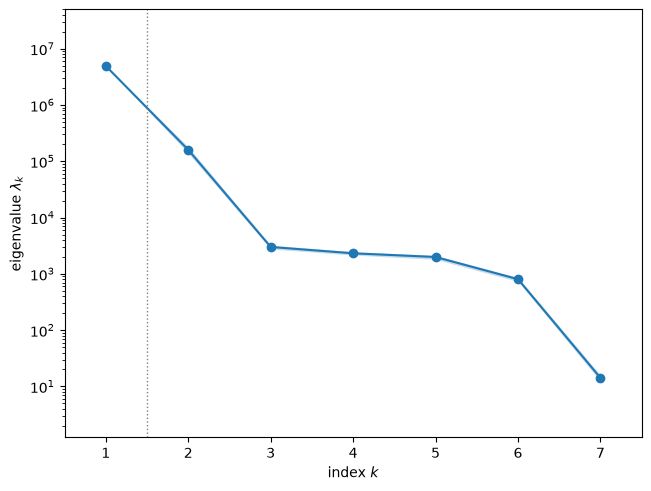

In [11]:
fig, ax = ac.plotting.plot_eigenvalues(sub_p)
plt.close(fig)
fig

For the pin-ended arch $\lambda_1/\lambda_2 = 30.9$ and $\lambda_2/\lambda_3 = 53.1$: two eigenvalues stand out ($\lambda_1$ alone carries 96.71 % of $\operatorname{tr}\mathbf C$). The gap rule, which compares differences, picks $n = 1$; because the ratio after $\lambda_2$ is larger than the one after $\lambda_1$, we also use the two-dimensional subspace below.

bootstrap mean subspace distance, k = 1..6: [5.1e-03 6.9e-03 1.3e-01 1.9e-01 4.3e-02 5.6e-03]


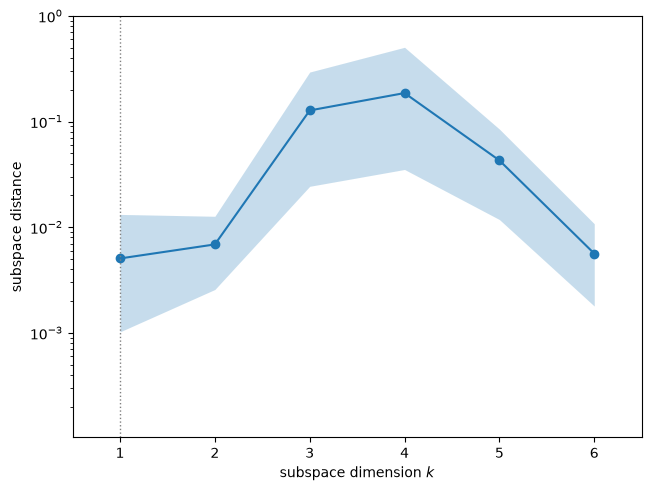

In [12]:
fig, ax = ac.plotting.plot_subspace_errors(sub_p)
plt.close(fig)
print('bootstrap mean subspace distance, k = 1..6:',
      np.array2string(sub_p.bootstrap_distances.mean(axis=0), formatter={'float_kind': '{:.1e}'.format}))
fig

The bootstrap mean distances are $5.1\times10^{-3}$ for $k = 1$ and $6.9\times10^{-3}$ for $k = 2$: both the one- and the two-dimensional subspaces are well determined, while $k = 3$ and $4$ (0.13, 0.19) are not.

w1 (pinned): S -0.481, Phi +0.280, E +0.378, D +0.590, B +0.303, tw +0.049, tf +0.323
w2 (pinned): S +0.323, Phi +0.835, E +0.194, D -0.368, B +0.082, tw +0.073, tf +0.115
|w1(pinned) . w1(fixed)| = 0.9943
direction of log lambda: |w2 . d| = 0.878; norm of its projection onto span(w1, w2) = 0.9959
direction of log N_cr:   |w1 . d| = 0.946; norm of its projection onto span(w1, w2) = 0.9995


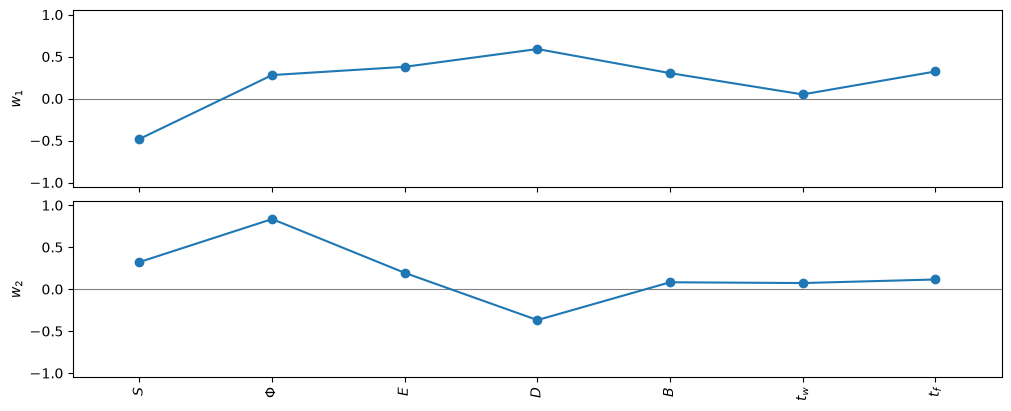

In [13]:
fig, axes = ac.plotting.plot_eigenvectors(sub_p, indices=[0, 1], labels=labels, figsize=(10, 4))
plt.close(fig)
w1p, w2p = sub_p.W[:, 0], sub_p.W[:, 1]
print('w1 (pinned):', ', '.join(f'{n} {w:+.3f}' for n, w in zip(am.NAMES, w1p)))
print('w2 (pinned):', ', '.join(f'{n} {w:+.3f}' for n, w in zip(am.NAMES, w2p)))
print(f'|w1(pinned) . w1(fixed)| = {abs(w1p @ w1f):.4f}')
# directions of log(lambda) and log(N_cr) in normalized coordinates (mean normalized gradients)
half = (am.UPPER - am.LOWER)/2
def ndir(fun):
    g = np.column_stack([(fun(X + h[j]*e) - fun(X - h[j]*e))/(2*h[j]) for j, e in enumerate(np.eye(7))]).mean(0)*half
    return g/np.linalg.norm(g)
d_lam = ndir(lambda Z: np.log(am.slenderness(Z)))
d_ncr = ndir(lambda Z: np.log(am.buckling_load(Z, 'fixed')/(am.CASES['fixed']['a'] + am.CASES['fixed']['b']*am.slenderness(Z)**2)))
sub_p2 = ac.with_dimension(sub_p, 2)
W2 = sub_p2.W[:, :2]
print(f'direction of log lambda: |w2 . d| = {abs(w2p @ d_lam):.3f}; norm of its projection onto span(w1, w2) = '
      f'{np.linalg.norm(W2.T @ d_lam):.4f}')
print(f'direction of log N_cr:   |w1 . d| = {abs(w1p @ d_ncr):.3f}; norm of its projection onto span(w1, w2) = '
      f'{np.linalg.norm(W2.T @ d_ncr):.4f}')
fig

The first pin-ended eigenvector is close to the fixed one ($|\mathbf w_1^{\text{pin}}\cdot\mathbf w_1^{\text{fix}}| = 0.9943$). The second is dominated by $\Phi$ (+0.835), with $D$ (−0.368) and $S$ (+0.323), and is close to the slenderness direction: $|\mathbf w_2\cdot\mathbf d_{\log\lambda}| = 0.878$, where $\mathbf d_{\log\lambda}$ is the unit mean normalized gradient of $\log\lambda$. The model is $N_{acr} = c(\lambda)\,N_{cr}$, a function of two quantities, and the directions of both lie almost entirely in the two-dimensional active subspace (projection norms 0.9959 for $\log\lambda$ and 0.9995 for $\log N_{cr}$). In log form, $\nabla\log N_{acr} = e(\lambda)\,\nabla\log\lambda + \nabla\log N_{cr}$ with the elasticity $e = d\log c/d\log\lambda$; a second direction appears when $e$ varies over the samples, and it varies much more for the pin-ended arch (next cell).

In [14]:
for case in ('fixed', 'pinned'):
    c, dc = am.coefficient(lam, case)
    e = dc*lam/c
    print(f'{case:6s}: c(lambda) in [{c.min():.3f}, {c.max():.3f}], elasticity e = dlog c/dlog lambda in '
          f'[{e.min():.2f}, {e.max():.2f}] (std {e.std():.3f})')

fixed : c(lambda) in [0.441, 0.589], elasticity e = dlog c/dlog lambda in [0.37, 0.78] (std 0.078)
pinned: c(lambda) in [0.594, 0.881], elasticity e = dlog c/dlog lambda in [0.29, 1.56] (std 0.283)


Over the samples the fixed-arch elasticity stays between 0.37 and 0.78 (standard deviation 0.078), but the pin-ended one runs from 0.29 to 1.56 (0.283): on the second branch $c$ has a square-root singularity at $\lambda = \sqrt{0.63}\,\pi^2 = 7.83$, just below the switch at 9.38, so $c$ rises steeply near the switch and flattens at large $\lambda$. The gradient direction therefore turns with $\lambda$, and the turn is what $\mathbf w_2$ captures.

correlation of N with y1: 0.9910; 41 samples on the first branch


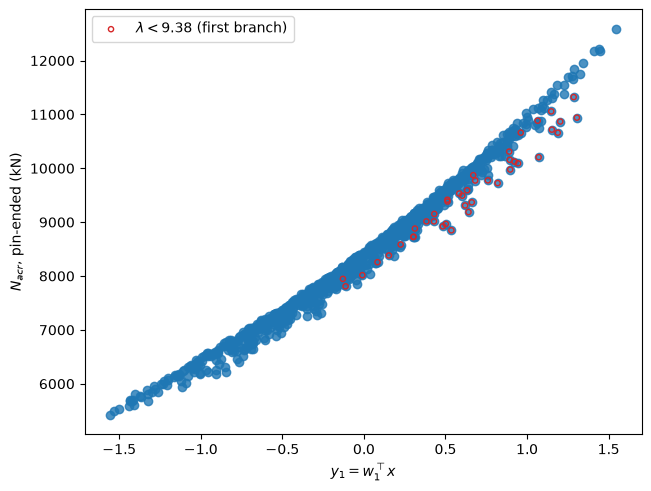

In [15]:
fig, ax = ac.plotting.plot_sufficient_summary(sub_p, X=X, f=f_pin, dims=1, qoi_label=r'$N_{acr}$, pin-ended (kN)')
y_p = space.to_normalized(X) @ W2
b1 = am.branch(X, 'pinned') == 1
ax.scatter(y_p[b1, 0], f_pin[b1], s=14, facecolors='none', edgecolors='C3', label=r'$\lambda < 9.38$ (first branch)')
ax.legend()
plt.close(fig)
print(f'correlation of N with y1: {np.corrcoef(y_p[:, 0], f_pin)[0, 1]:.4f}; {b1.sum()} samples on the first branch')
fig

y2 range [-1.35, 1.51]; correlation of y2 with lambda: 0.8726; first-branch samples at y1 in [-0.13, 1.31], y2 in [-1.35, -0.57]


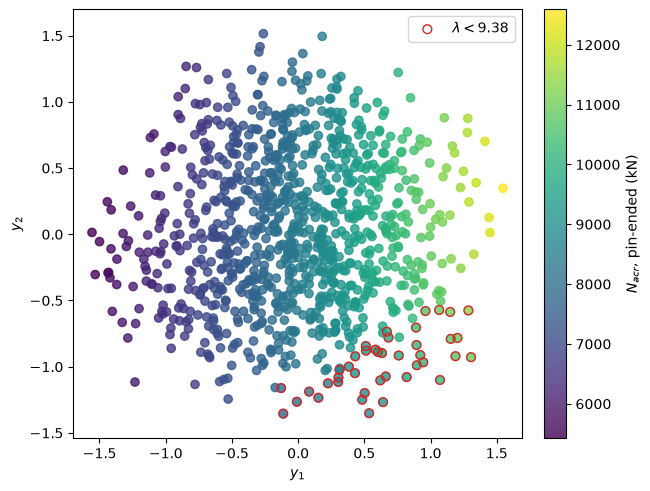

In [16]:
fig, ax = ac.plotting.plot_sufficient_summary(sub_p2, X=X, f=f_pin, dims=2, qoi_label=r'$N_{acr}$, pin-ended (kN)')
ax.scatter(y_p[b1, 0], y_p[b1, 1], s=40, facecolors='none', edgecolors='C3', label=r'$\lambda < 9.38$')
ax.legend()
plt.close(fig)
r2 = np.corrcoef(y_p[:, 1], lam)[0, 1]
print(f'y2 range [{y_p[:, 1].min():.2f}, {y_p[:, 1].max():.2f}]; correlation of y2 with lambda: {r2:.4f}; '
      f'first-branch samples at y1 in [{y_p[b1, 0].min():.2f}, {y_p[b1, 0].max():.2f}], y2 in [{y_p[b1, 1].min():.2f}, {y_p[b1, 1].max():.2f}]')
fig

Against $y_1$ alone the pin-ended load still follows a clear trend (correlation 0.9910), with vertical scatter from $y_2$. In the $(y_1, y_2)$ plane the colour varies smoothly along $y_1$, and the 41 samples on the first branch ($\lambda < 9.38$, red circles) sit in the lower right corner ($y_1 \ge -0.13$, $y_2 \le -0.57$), at the low end of $y_2$, which follows the slenderness (correlation with $\lambda$: 0.8726). The 1.6 % jump at the switch is too small to see at this scale; the gradient-based estimate does not account for it.

### Surrogates on the active variables

We fit polynomials in the active variables and report the leave-one-out $R^2$: a quadratic in $y_1$ for the fixed arch, and quadratics in $y_1$ and in $(y_1, y_2)$ for the pin-ended arch.

LOO R^2: fixed, quadratic in y1 0.99837; pinned, quadratic in y1 0.98867; pinned, quadratic in (y1, y2) 0.99851


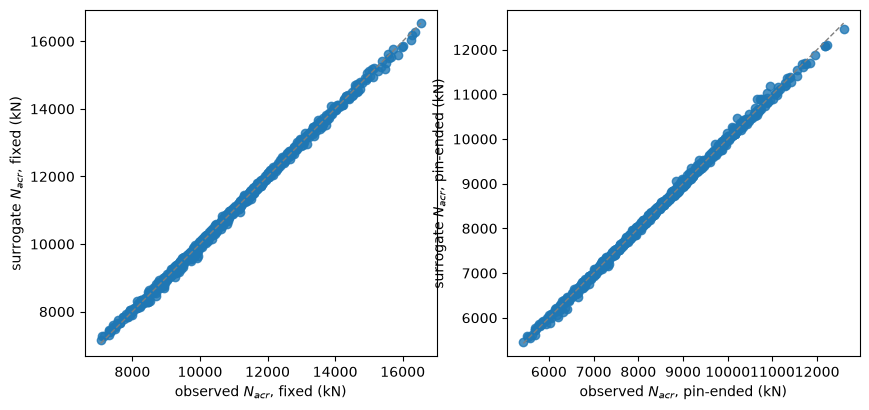

In [17]:
sur_f = ac.fit_surrogate(X=X, f=f_fix, subspace=ac.with_dimension(sub_f, 1), kind='poly', degree=2)
sur_p1 = ac.fit_surrogate(X=X, f=f_pin, subspace=ac.with_dimension(sub_p, 1), kind='poly', degree=2)
sur_p2 = ac.fit_surrogate(X=X, f=f_pin, subspace=sub_p2, kind='poly', degree=2)
print(f'LOO R^2: fixed, quadratic in y1 {sur_f.loo_r_squared:.5f}; pinned, quadratic in y1 '
      f'{sur_p1.loo_r_squared:.5f}; pinned, quadratic in (y1, y2) {sur_p2.loo_r_squared:.5f}')
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
ac.plotting.plot_surrogate_fit(sur_f, X=X, f=f_fix, qoi_label=r'$N_{acr}$, fixed (kN)', ax=axes[0])
ac.plotting.plot_surrogate_fit(sur_p2, X=X, f=f_pin, qoi_label=r'$N_{acr}$, pin-ended (kN)', ax=axes[1])
plt.close(fig)
fig

The quadratic in one active variable has leave-one-out $R^2 = 0.99837$ for the fixed arch. For the pin-ended arch the same one-variable quadratic reaches 0.98867, and a quadratic in the two active variables 0.99851. Seven-input models of the buckling load can be replaced by one (fixed) or two (pin-ended) linear combinations of the normalized inputs.

### Comparison with the paper

The paper [[1]](https://doi.org/10.48084/etasr.3833) reports Sobol' indices from 100,000 Monte Carlo runs per case (Tables III–IV, Figs. 6 and 8), not an active subspace. We estimate first-order and total Sobol' indices of our model with the Saltelli et al. [[3]](https://doi.org/10.1016/j.cpc.2009.09.018) first-order and Jansen total-effect estimators on $2^{17}$ base samples (9 × 131,072 model runs, under a second), and give the squared first eigenvector for reference (for a near-linear function of independent uniform inputs, $w_{1j}^2$ approximates the first-order index of input $j$).

In [18]:
def sobol(case, n=2**17, seed=SEED):
    rng = np.random.default_rng(seed)
    A, B = am.sample(n, rng), am.sample(n, rng)
    fA, fB = am.buckling_load(A, case), am.buckling_load(B, case)
    mu = np.mean(np.r_[fA, fB]); fA, fB = fA - mu, fB - mu    # centring lowers the estimator variance
    V = np.var(np.r_[fA, fB])
    S1, ST = np.empty(7), np.empty(7)
    for j in range(7):
        ABj = A.copy(); ABj[:, j] = B[:, j]
        fj = am.buckling_load(ABj, case) - mu
        S1[j], ST[j] = np.mean(fB*(fj - fA))/V, 0.5*np.mean((fA - fj)**2)/V
    return S1, ST
paper = {'fixed':  {'S': (0.2942, 0.2819), 'E': (0.0795, 0.0690), 'D': (0.6577, 0.6510), 'B': (0.0425, None),
                    'tw': (0.0425, None), 'tf': (0.0425, None), 'Phi': (0.0425, None)},
         'pinned': {'S': (0.2337, 0.2788), 'E': (0.0472, 0.0738), 'D': (0.6611, 0.6844), 'B': (0.2337, None),
                    'tw': (None, None), 'tf': (None, None), 'Phi': (None, None)}}
fmt = lambda v: '-' if v is None else f'{v:.4f}'
sob = {}
for case, sub in (('fixed', sub_f), ('pinned', sub_p)):
    S1, ST = sob[case] = sobol(case)
    print(f'{case}: input   paper S_i  paper S_Ti   S_i     S_Ti    w1_j^2')
    for j, n in enumerate(am.NAMES):
        p1, pT = paper[case][n]
        print(f'        {n:5s} {fmt(p1):>9s} {fmt(pT):>10s}  {S1[j]:.4f}  {ST[j]:.4f}  {sub.W[j, 0]**2:.4f}')
    print(f'        L     {"0.0425" if case == "fixed" else "-":>9s} {"-":>10s}  0 (not an input)')

fixed: input   paper S_i  paper S_Ti   S_i     S_Ti    w1_j^2
        S        0.2942     0.2819  0.2709  0.2762  0.2793
        Phi      0.0425          -  0.0380  0.0376  0.0368
        E        0.0795     0.0690  0.1257  0.1291  0.1265
        D        0.6577     0.6510  0.3717  0.3803  0.3758
        B        0.0425          -  0.0861  0.0859  0.0851
        tw       0.0425          -  0.0020  0.0018  0.0018
        tf       0.0425          -  0.0941  0.0973  0.0948
        L        0.0425          -  0 (not an input)


pinned: input   paper S_i  paper S_Ti   S_i     S_Ti    w1_j^2
        S        0.2337     0.2788  0.2314  0.2368  0.2316
        Phi           -          -  0.0773  0.0889  0.0785
        E        0.0472     0.0738  0.1396  0.1428  0.1431
        D        0.6611     0.6844  0.3406  0.3499  0.3483
        B        0.2337          -  0.0907  0.0904  0.0919
        tw            -          -  0.0026  0.0026  0.0024
        tf            -          -  0.1013  0.1041  0.1042
        L             -          -  0 (not an input)


| Quantity | Paper value | Notebook value |
|---|---|---|
| Inputs | 8 independent uniforms, Table II ($S$, $L$, $\Phi$, $E$, $D$, $B$, $t_w$, $t_f$) | 7 ($L$ dropped: not in the formulas, and fixed by $S$ and $\Phi$) |
| Span $L$ implied by $S$, $\Phi$ (m) | 9.00–10.00 (Table II, sampled independently) | 6.13–7.55 |
| Young's modulus (MPa) | 18E5–22E5 (Table II) | $1.8\times10^5$–$2.2\times10^5$ |
| Samples | 100,000 per case, MATLAB, 67.0 and 69.0 min | 1000 with exact gradients; $9\times2^{17}$ runs per case for Sobol' indices |
| Fixed: first-order $S_D$, $S_S$, $S_E$ | 0.6577, 0.2942, 0.0795 (Table III); text: 53 %, 24 %, 6 % | 0.3717, 0.2709, 0.1257 |
| Fixed: total $S_{T,D}$, $S_{T,S}$, $S_{T,E}$ | 0.6510, 0.2819, 0.0690 (Table III); text: 65 %, 28 %, 7 % | 0.3803, 0.2762, 0.1291 |
| Fixed: first-order $B$, $t_w$, $t_f$, $\Phi$, $L$ | 0.0425 each (Table III) | 0.0861, 0.0020, 0.0941, 0.0380, 0 |
| Pin-ended: first-order $S_D$, $S_S$, $S_E$ | 0.6611, 0.2337, 0.0472 (Table IV); text: 60 %, 26 %, 6 % | 0.3406, 0.2314, 0.1396 |
| Pin-ended: total $S_{T,D}$, $S_{T,S}$, $S_{T,E}$ | 0.6844, 0.2788, 0.0738 (Table IV); text: 64 %, 28 %, 7 % | 0.3499, 0.2368, 0.1428 |
| Pin-ended: first-order $B$, $t_w$, $t_f$, $\Phi$ | 0.2337, –, –, – (Table IV) | 0.0907, 0.0026, 0.1013, 0.0773 |
| Active subspace | not reported | fixed: $n = 1$, $\lambda_1/\lambda_2 = 401.7$; pin-ended: $\lambda_1/\lambda_2 = 30.9$, $\lambda_2/\lambda_3 = 53.1$ ($n = 2$ used) |

We agree with the paper that $D$ and $S$ are the two most influential inputs, in that order, for both support conditions. The magnitudes differ: our model gives $D$ about half the paper's share, and the flange thickness $t_f$ (0.09–0.10) and flange width $B$ (0.09) nearly as much as $E$ (0.13–0.14), where the paper reports 0.0425 for every minor input. The paper's tables are not self-consistent (in Table III the first-order indices of $S$, $E$ and $D$ exceed their total indices, five inputs share the value 0.0425, and the indices sum to 1.24; in Table IV $B$ repeats the value of $S$; the text quotes other percentages), and it does not give its section formulas, so we cannot tell where the difference comes from. The first eigenvector reproduces the ranking of our Sobol' indices ($w_{1j}^2$: $D$ 0.38, $S$ 0.28, $E$ 0.13, $t_f$ 0.09, $B$ 0.09).

### References

[1] T.-H. Nguyen. [Global sensitivity analysis of in-plane elastic buckling of steel arches](https://doi.org/10.48084/etasr.3833). *Engineering, Technology & Applied Science Research*, 10(5):6476–6480, 2020.

[2] Y.-L. Pi, M. A. Bradford, and B. Uy. [In-plane stability of arches](https://doi.org/10.1016/S0020-7683(01)00209-8). *International Journal of Solids and Structures*, 39(1):105–125, 2002.

[3] A. Saltelli, P. Annoni, I. Azzini, F. Campolongo, M. Ratto, and S. Tarantola. [Variance based sensitivity analysis of model output. Design and estimator for the total sensitivity index](https://doi.org/10.1016/j.cpc.2009.09.018). *Computer Physics Communications*, 181(2):259–270, 2010.

[4] P. G. Constantine. [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860). SIAM, 2015.

[R1]: https://doi.org/10.48084/etasr.3833
[R2]: https://doi.org/10.1016/S0020-7683(01)00209-8
[R3]: https://doi.org/10.1016/j.cpc.2009.09.018

### Acknowledgments

From [[1]][R1]: "This research was funded by the Vinh University."

In [19]:
print(f'Total run time: {time.perf_counter() - t_start:.1f} s')

Total run time: 8.0 s
